# Bike Sharing Rental Prediction using Machine Learning

## Business Problem

The objective of this project is to analyze the Bike Sharing Rental dataset and identify the factors affecting bike rental demand. This analysis helps companies optimize bike availability, improve customer satisfaction, and make better operational decisions.

# 1. Exploratory Data Analysis (EDA)

In [1]:
# Import necessary libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Display all columns
pd.set_option('display.max_columns', None)

In [2]:
# Load Dataset
df = pd.read_csv("Dataset.csv")

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Convert columns to numeric
cols = ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
df[cols] = df[cols].apply(pd.to_numeric, errors='coerce')

# Fill missing values (if any)
df.fillna(df.median(numeric_only=True), inplace=True)

# Display first five rows

df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,01-01-2011,springer,2011,1,0,No,6,No work,Clear,0.24,0.2879,0.81,0.0,3.0,13.0,16
1,2,01-01-2011,springer,2011,1,1,No,6,No work,Clear,0.22,0.2727,0.80,0.0,8.0,32.0,40
2,3,01-01-2011,springer,2011,1,2,No,6,No work,Clear,0.22,0.2727,0.63,0.0,5.0,27.0,32
3,4,01-01-2011,springer,2011,1,3,No,6,No work,Clear,0.24,0.2879,0.75,0.0,3.0,10.0,13
4,5,01-01-2011,springer,2011,1,4,No,6,No work,Clear,0.24,0.2879,0.75,0.0,0.0,1.0,1


# The dataset has multiple weather and seasonal attributes along with the target variable 'count', representing the total number of bike rentals.

In [3]:
df.shape

(17379, 17)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  object 
 3   yr          17379 non-null  object 
 4   mnth        17379 non-null  object 
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  object 
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  object 
 9   weathersit  17379 non-null  object 
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  float64
 15  registered  17379 non-null  float64
 16  cnt         17379 non-null  int64  
dtypes: float64(6), int64(4), object(7)
memory usage: 2.3+ MB


### Most variables are numerical while a few are categorical.

In [5]:
# Check missing values
print("Missing values before handling:")
print(df.isnull().sum())

# Handle missing values only if present
if df.isnull().sum().sum() > 0:
    df.fillna(df.median(numeric_only=True), inplace=True)
    print("\nMissing values have been handled using median imputation.")
else:
    print("\nNo missing values found in the dataset.")

Missing values before handling:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

No missing values found in the dataset.


### No missing values are present in the dataset.

In [6]:
df.duplicated().sum()

np.int64(0)

### No duplicate records are found.

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
instant,17379.0,8690.000000,5017.029500,1.00,4345.5000,8690.0000,13034.5000,17379.0000
hr,17379.0,11.546752,6.914405,0.00,6.0000,12.0000,18.0000,23.0000
weekday,17379.0,3.003683,2.005771,0.00,1.0000,3.0000,5.0000,6.0000
temp,17379.0,0.497133,0.192464,0.02,0.3400,0.5000,0.6600,1.0000
atemp,17379.0,0.475854,0.171800,0.00,0.3333,0.4848,0.6212,1.0000
hum,17379.0,0.627209,0.192906,0.00,0.4800,0.6300,0.7800,1.0000
windspeed,17379.0,0.190081,0.122303,0.00,0.1045,0.1940,0.2537,0.8507
casual,17379.0,35.675528,49.305208,0.00,4.0000,17.0000,48.0000,367.0000
registered,17379.0,153.790322,151.355717,0.00,34.0000,115.0000,220.0000,886.0000
cnt,17379.0,189.463088,181.387599,1.00,40.0000,142.0000,281.0000,977.0000


#### The bike rental count varies significantly, indicating demand fluctuations.

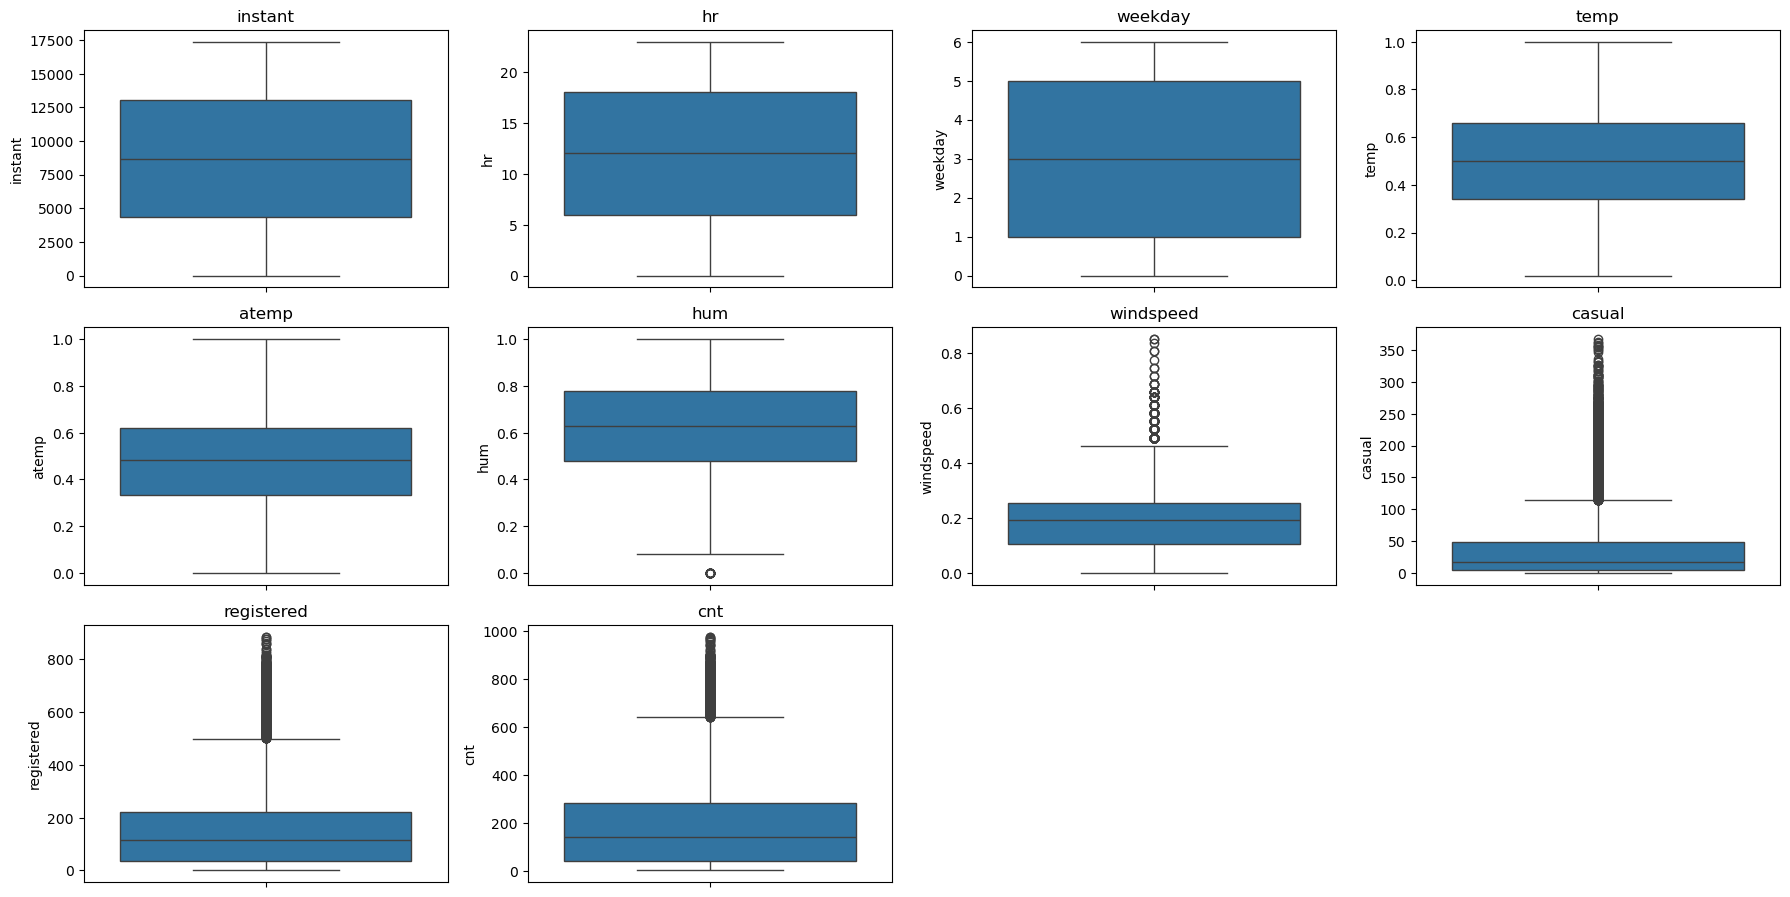

In [8]:
# Detect outliers

numeric_columns = df.select_dtypes(include=np.number).columns

plt.figure(figsize=(18,12))

for i,col in enumerate(numeric_columns,1):

    plt.subplot(4,4,i)
    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

#### Few numerical variables contain outliers, which may represent seasonal demand spikes rather than errors.

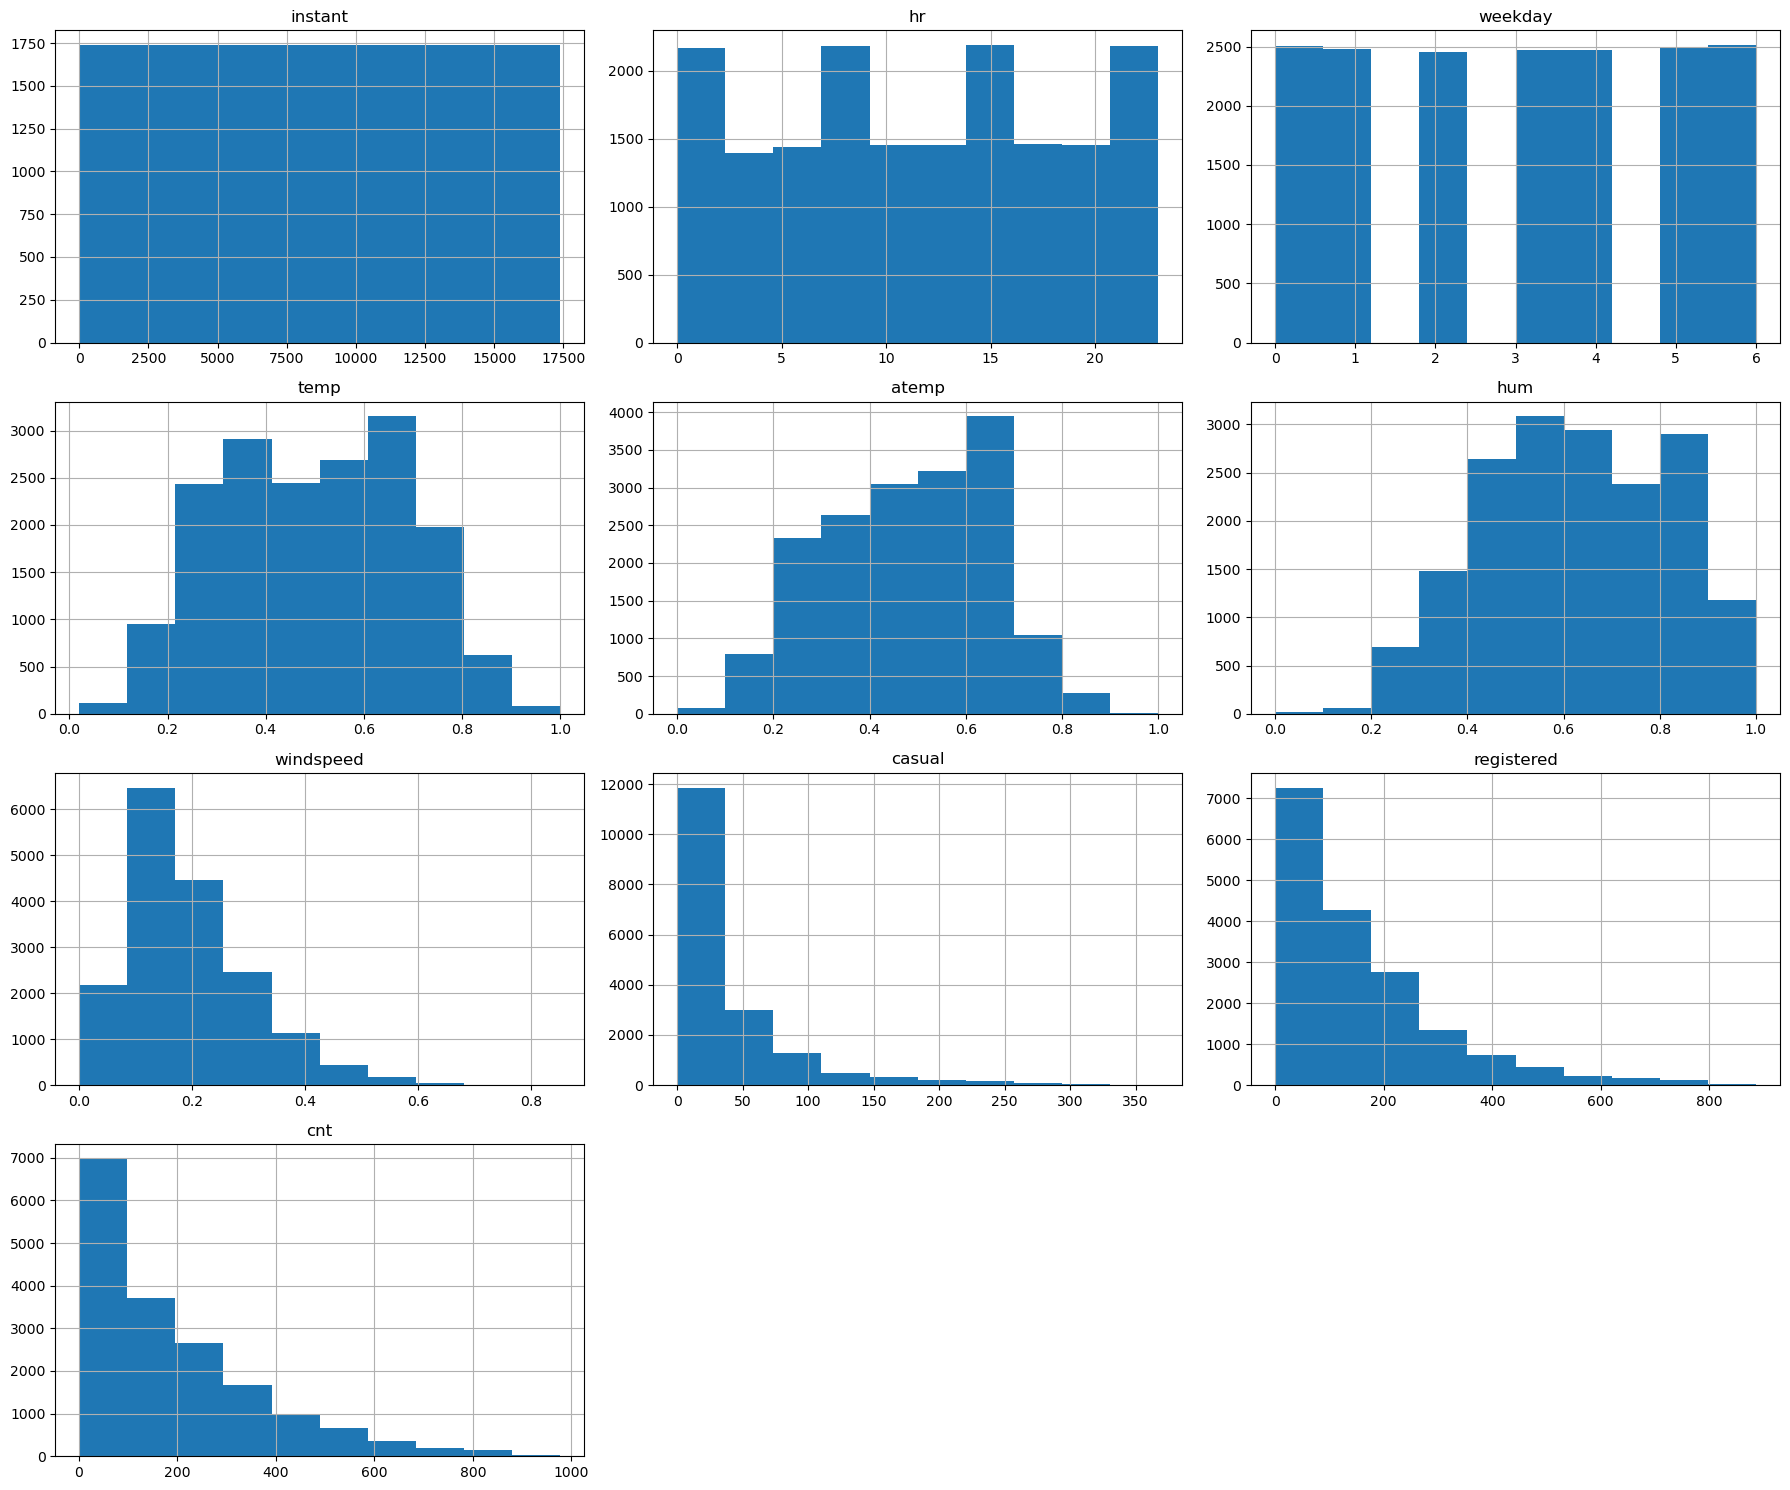

In [9]:
df.hist(figsize=(18,15))
plt.tight_layout()
plt.show()

#### Most weather-related variables are approximately normally distributed whereas bike count is positively skewed.

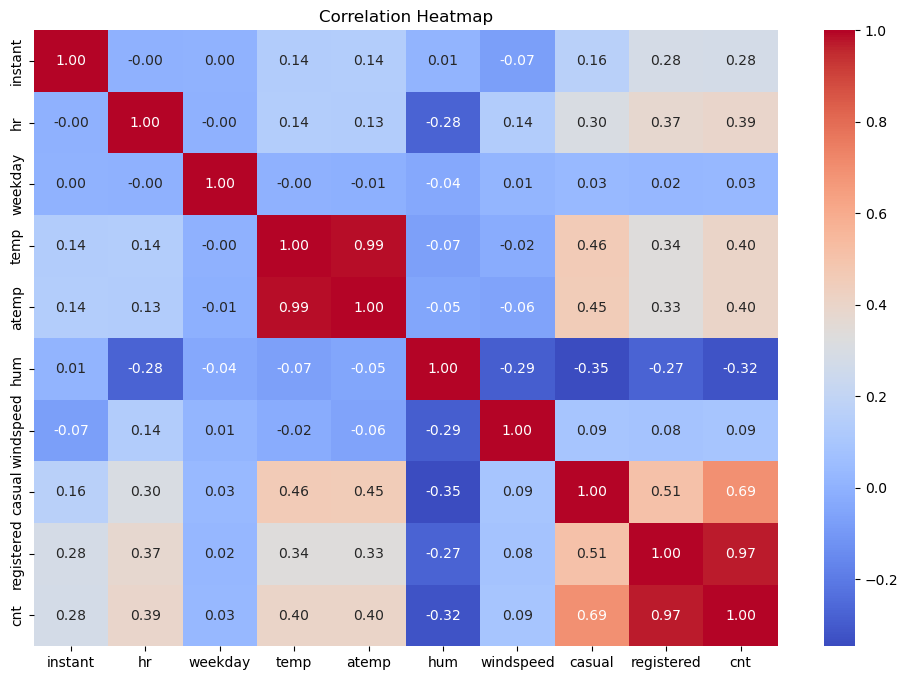

In [10]:
plt.figure(figsize=(12,8))

sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            cmap='coolwarm',
            fmt=".2f")

plt.title("Correlation Heatmap")

plt.show()

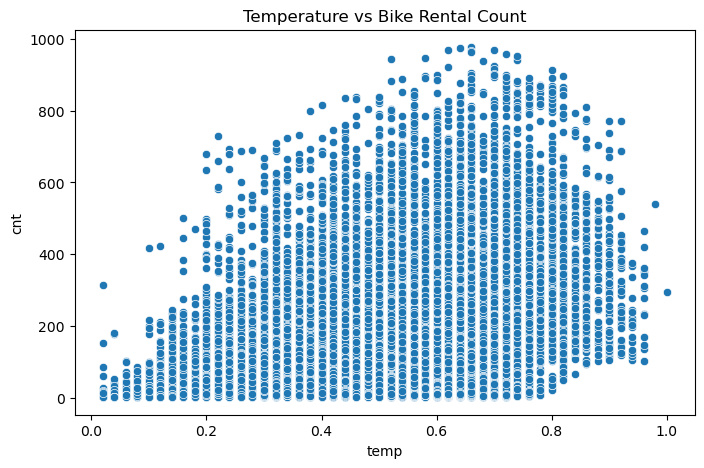

In [11]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x='temp', y='cnt')
plt.title("Temperature vs Bike Rental Count")
plt.show()

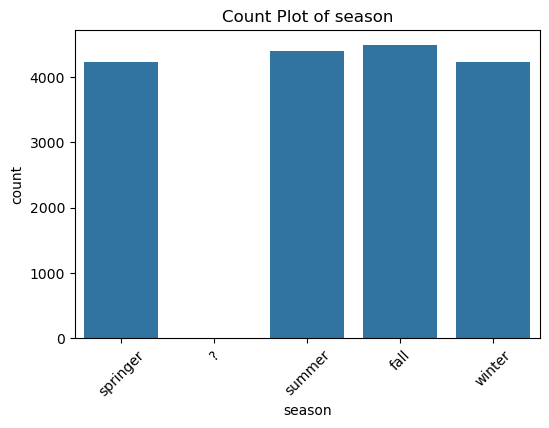

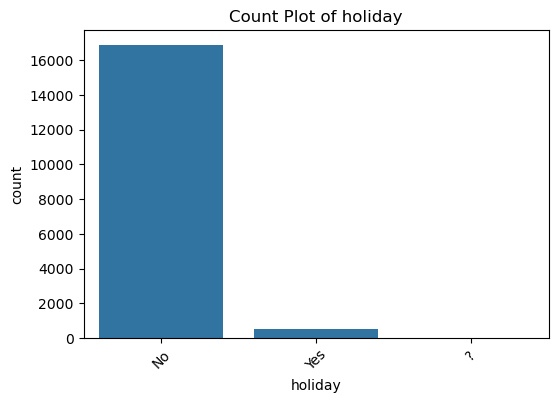

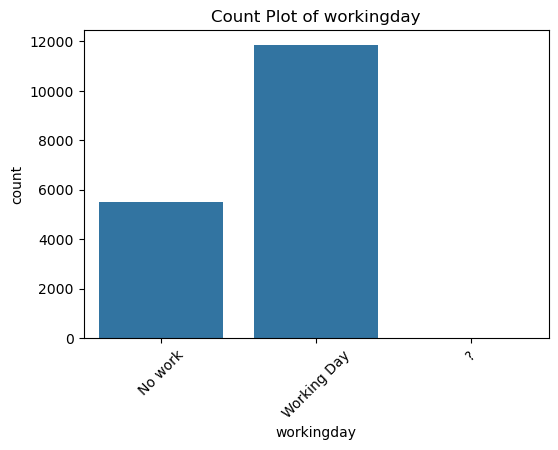

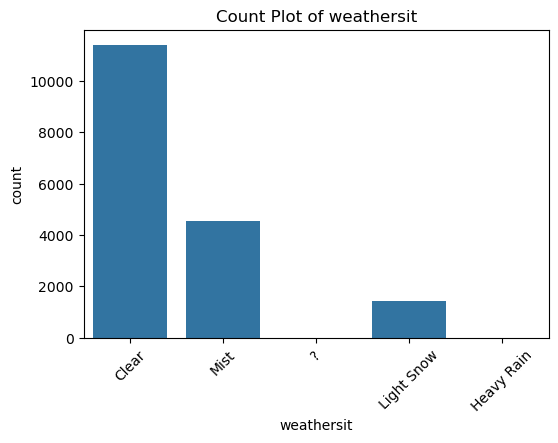

In [12]:
categorical_cols = ['season', 'holiday', 'workingday', 'weathersit']

for col in categorical_cols:
    if col in df.columns:
        plt.figure(figsize=(6,4))
        sns.countplot(data=df, x=col)
        plt.title(f'Count Plot of {col}')
        plt.xticks(rotation=45)
        plt.show()
    else:
        print(f"Column '{col}' not found in dataset.")

# 2. Time Series Analysis

## Objective

Analyze the trend of bike rental demand over time using the date column (`dteday`).

This helps identify seasonality and overall rental patterns.

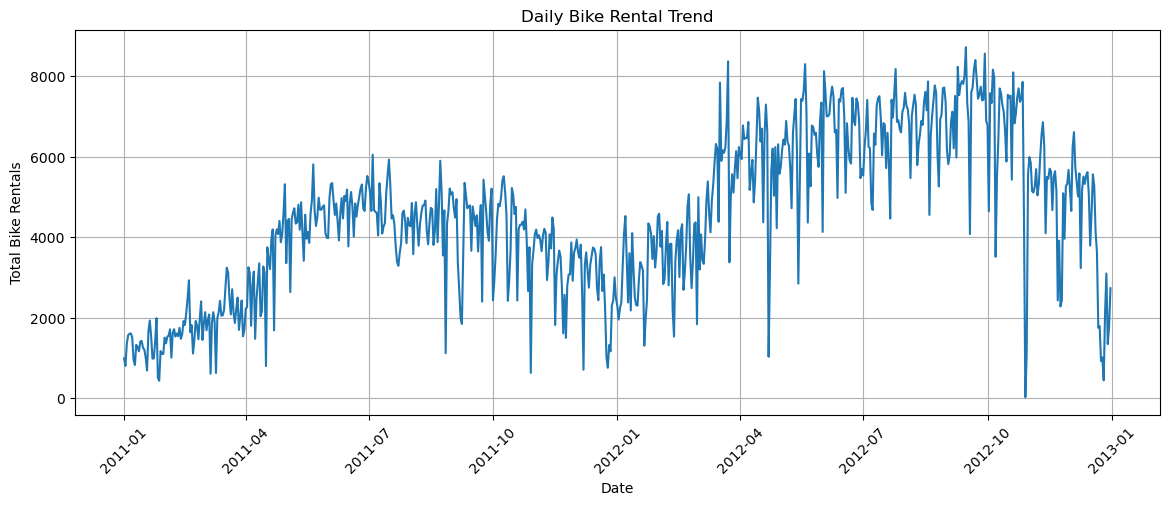

In [13]:
# Convert dteday to datetime
df['dteday'] = pd.to_datetime(df['dteday'], format='%d-%m-%Y')

# Daily bike rentals
daily_rentals = df.groupby('dteday')['cnt'].sum()

plt.figure(figsize=(14,5))
plt.plot(daily_rentals.index, daily_rentals.values)
plt.title("Daily Bike Rental Trend")
plt.xlabel("Date")
plt.ylabel("Total Bike Rentals")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

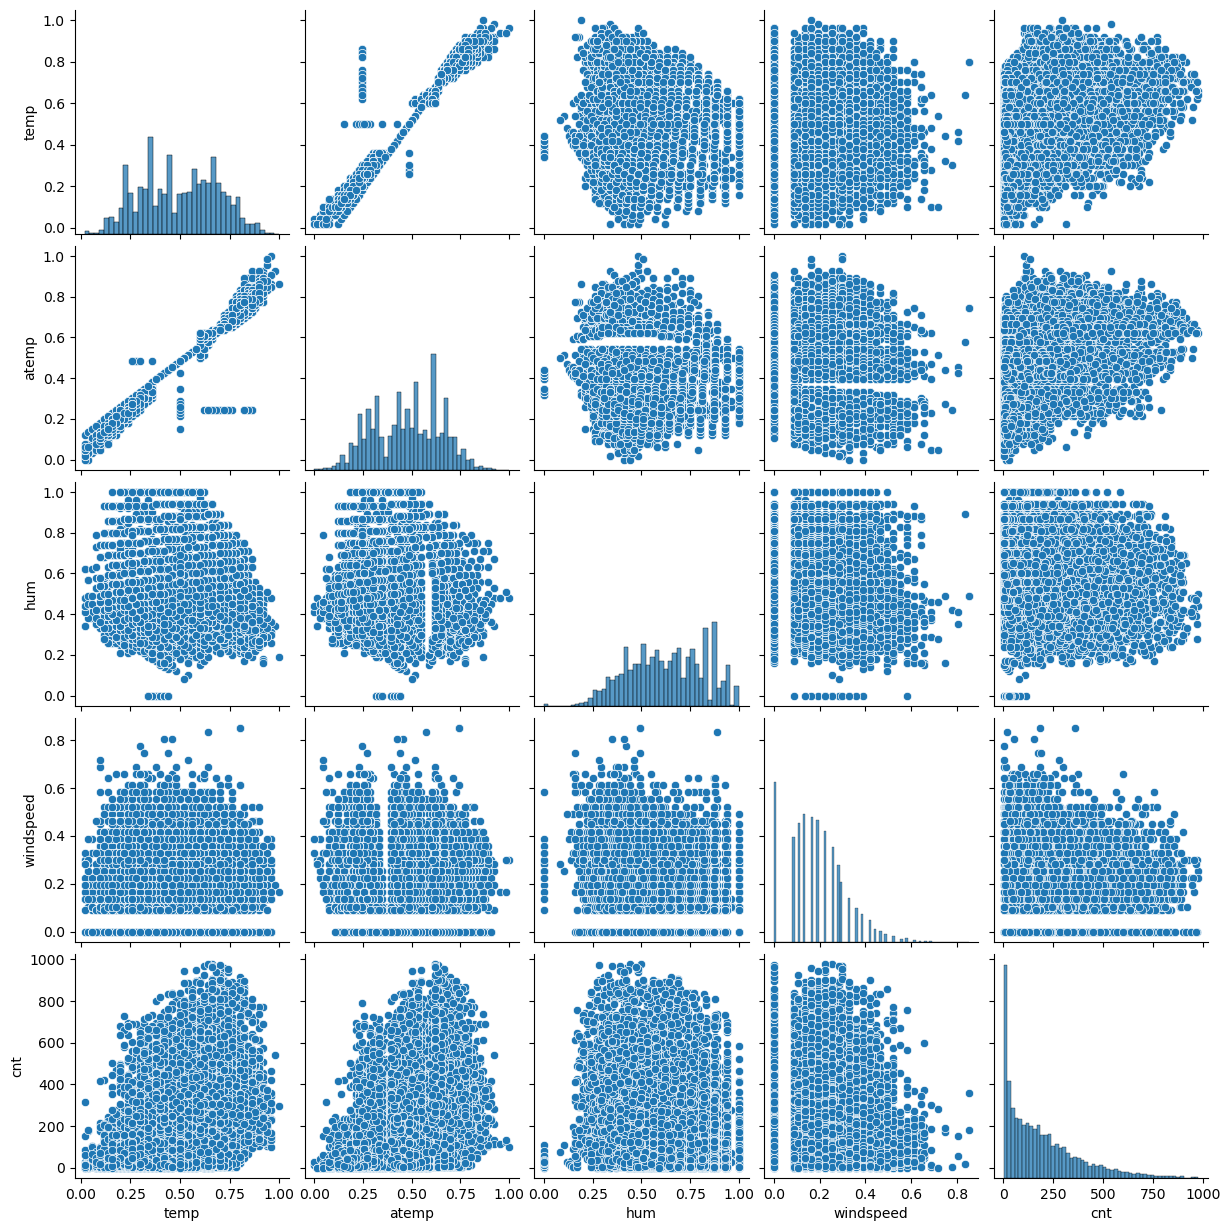

In [14]:
# Pairplot for important numerical variables

sns.pairplot(
    df[['temp', 'atemp', 'hum', 'windspeed', 'cnt']]
)

plt.show()

### Bike demand increases with temperature and decreases with humidity.

### 1. Temperature positively impacts rentals.

### 2. Humidity negatively impacts rentals.

### 3. Working days experience higher rentals.

### 4. Clear weather has maximum demand.

### 5. Extreme weather reduces rentals.

### 6. Demand varies across seasons.

### 7. Holidays witness comparatively lower rentals.

### 8. Rental companies should increase bike availability during high-demand seasons.

## EDA reveals that weather, season, temperature, and working days significantly influence bike rental demand. These insights can help companies optimize inventory, improve customer satisfaction, and maximize revenue.

# 3. Feature Engineering

## Objective

Feature engineering improves model performance by creating useful features and preparing the dataset for machine learning.

The following steps are performed:

- Create a new feature (`is_peak_hour`)
- Encode categorical variables
- Remove unnecessary columns

In [15]:
# Create Peak Hour Feature

df['is_peak_hour'] = df['hr'].apply(lambda x: 1 if (7 <= x <= 9) or (17 <= x <= 19) else 0)

print(df[['hr', 'is_peak_hour']].head())

   hr  is_peak_hour
0   0             0
1   1             0
2   2             0
3   3             0
4   4             0


### Feature Scaling

Numerical features are standardized using StandardScaler.

Note: Tree-based models (Decision Tree, Random Forest, and Gradient Boosting)
do not require feature scaling. However, this step is included to demonstrate
a complete preprocessing pipeline and satisfy the preprocessing requirements
of the project.

[Code Cell]
from sklearn.preprocessing import StandardScaler
...

In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

numerical_cols = ['temp', 'atemp', 'hum', 'windspeed']

df[numerical_cols] = scaler.fit_transform(df[numerical_cols])

print(df[numerical_cols].head())

       temp     atemp       hum  windspeed
0 -1.336047 -1.094064  0.947596  -1.554228
1 -1.439966 -1.182542  0.895755  -1.554228
2 -1.439966 -1.182542  0.014470  -1.554228
3 -1.336047 -1.094064  0.636554  -1.554228
4 -1.336047 -1.094064  0.636554  -1.554228


In [17]:
# Import required libraries

import pandas as pd
import numpy as np

In [18]:
# Make a copy of the dataset

bike_df = df.copy()

# Display first five rows

bike_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,is_peak_hour
0,1,2011-01-01,springer,2011,1,0,No,6,No work,Clear,-1.336047,-1.094064,0.947596,-1.554228,3.0,13.0,16,0
1,2,2011-01-01,springer,2011,1,1,No,6,No work,Clear,-1.439966,-1.182542,0.895755,-1.554228,8.0,32.0,40,0
2,3,2011-01-01,springer,2011,1,2,No,6,No work,Clear,-1.439966,-1.182542,0.014470,-1.554228,5.0,27.0,32,0
3,4,2011-01-01,springer,2011,1,3,No,6,No work,Clear,-1.336047,-1.094064,0.636554,-1.554228,3.0,10.0,13,0
4,5,2011-01-01,springer,2011,1,4,No,6,No work,Clear,-1.336047,-1.094064,0.636554,-1.554228,0.0,1.0,1,0


In [19]:
# Drop unnecessary columns

bike_df = bike_df.drop(columns=['instant','dteday','casual','registered'])

bike_df.head()

,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt,is_peak_hour
0,springer,2011,1,0,No,6,No work,Clear,-1.336047,-1.094064,0.947596,-1.554228,16,0
1,springer,2011,1,1,No,6,No work,Clear,-1.439966,-1.182542,0.895755,-1.554228,40,0
2,springer,2011,1,2,No,6,No work,Clear,-1.439966,-1.182542,0.014470,-1.554228,32,0
3,springer,2011,1,3,No,6,No work,Clear,-1.336047,-1.094064,0.636554,-1.554228,13,0
4,springer,2011,1,4,No,6,No work,Clear,-1.336047,-1.094064,0.636554,-1.554228,1,0


### Observation

The columns 'instant' and 'dteday' do not contribute to predicting bike demand.

The columns 'casual' and 'registered' were removed because:

cnt = casual + registered

Using them would leak target information into the model.

In [20]:
# Convert categorical columns into numerical format

bike_df = pd.get_dummies(
    bike_df,
    columns=['season','yr','mnth','holiday','workingday','weathersit'],
    drop_first=True
)

bike_df.head()

,hr,weekday,temp,atemp,hum,windspeed,cnt,is_peak_hour,season_fall,season_springer,season_summer,season_winter,yr_2012,yr_?,mnth_10,mnth_11,mnth_12,mnth_2,mnth_3,mnth_4,mnth_5,mnth_6,mnth_7,mnth_8,mnth_9,mnth_?,holiday_No,holiday_Yes,workingday_No work,workingday_Working Day,weathersit_Clear,weathersit_Heavy Rain,weathersit_Light Snow,weathersit_Mist
0,0,6,-1.336047,-1.094064,0.947596,-1.554228,16,0,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False,True,False,False,False
1,1,6,-1.439966,-1.182542,0.895755,-1.554228,40,0,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False,True,False,False,False
2,2,6,-1.439966,-1.182542,0.014470,-1.554228,32,0,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False,True,False,False,False
3,3,6,-1.336047,-1.094064,0.636554,-1.554228,13,0,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False,True,False,False,False
4,4,6,-1.336047,-1.094064,0.636554,-1.554228,1,0,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False,True,False,True,False,False,False


### Observation

Categorical variables were converted into dummy variables using One-Hot Encoding.

This allows machine learning algorithms to understand categorical information without introducing ordinal relationships.

In [21]:
# Define independent and dependent variables

X = bike_df.drop('cnt', axis=1)

y = bike_df['cnt']

print("Shape of X :", X.shape)
print("Shape of y :", y.shape)

Shape of X : (17379, 33)
Shape of y : (17379,)


In [22]:
# Display feature names

print(X.columns)

Index(['hr', 'weekday', 'temp', 'atemp', 'hum', 'windspeed', 'is_peak_hour',
       'season_fall', 'season_springer', 'season_summer', 'season_winter',
       'yr_2012', 'yr_?', 'mnth_10', 'mnth_11', 'mnth_12', 'mnth_2', 'mnth_3',
       'mnth_4', 'mnth_5', 'mnth_6', 'mnth_7', 'mnth_8', 'mnth_9', 'mnth_?',
       'holiday_No', 'holiday_Yes', 'workingday_No work',
       'workingday_Working Day', 'weathersit_Clear', 'weathersit_Heavy Rain',
       'weathersit_Light Snow', 'weathersit_Mist'],
      dtype='object')


### Observation

The feature matrix contains all predictor variables except the target variable (cnt).

The target variable has been stored separately in y.

In [23]:
# Import train-test split

from sklearn.model_selection import train_test_split

In [24]:
# Split the dataset

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features :", X_train.shape)
print("Testing Features :", X_test.shape)

print("Training Target :", y_train.shape)
print("Testing Target :", y_test.shape)

Training Features : (13903, 33)
Testing Features : (3476, 33)
Training Target : (13903,)
Testing Target : (3476,)


### Observation

The dataset has been divided into training and testing sets.

80% of the data is used for training while 20% is reserved for testing to evaluate the model on unseen data.

# 4. Data Validation Before Model Building

Before training the models, the dataset was verified to ensure it is ready for machine learning.

Checks performed:
- No missing values
- No duplicate records
- Correct data types
- Encoded categorical variables
- Scaled numerical features

In [25]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (17379, 18)

Missing Values:
instant         0
dteday          0
season          0
yr              0
mnth            0
hr              0
holiday         0
weekday         0
workingday      0
weathersit      0
temp            0
atemp           0
hum             0
windspeed       0
casual          0
registered      0
cnt             0
is_peak_hour    0
dtype: int64

Duplicate Records: 0

Data Types:
instant                  int64
dteday          datetime64[ns]
season                  object
yr                      object
mnth                    object
hr                       int64
holiday                 object
weekday                  int64
workingday              object
weathersit              object
temp                   float64
atemp                  float64
hum                    float64
windspeed              float64
casual                 float64
registered             float64
cnt                      int64
is_peak_hour             int64
dtype: object


# 5. Model Building

## Objective

Different regression algorithms are trained to predict hourly bike rental demand.

The following models are implemented:

- Model 1 – Decision Tree Regressor
- Model 2 – Random Forest Regressor
- Model 3 – Gradient Boosting Regressor
- Model 4 – Linear Regression
- Model 5 – Extra Trees Regressor

# Model Building 1 - Decision Tree Regressor

## Objective

A Decision Tree Regressor is a supervised machine learning algorithm used for predicting continuous numerical values.

It learns decision rules from the training data and predicts the target variable by recursively splitting the dataset based on feature values.

In this project, the Decision Tree Regressor is used to predict the total number of bike rentals (`cnt`).

In [26]:
# Import Decision Tree Regressor

from sklearn.tree import DecisionTreeRegressor

In [27]:
# Create Decision Tree model

dt_model = DecisionTreeRegressor(random_state=42)

# Train the model

dt_model.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


### Observation

The Decision Tree model has been successfully trained using the training dataset.

The trained model will now be used to predict bike rental demand on the testing dataset.

In [28]:
# Predict on test data

dt_pred = dt_model.predict(X_test)

# Display first 10 predictions

print(dt_pred[:10])

[392.  95.  12. 487.  12.  68. 752.  28.   9.  28.]


In [29]:
# Import evaluation metrics

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

In [30]:
# Calculate evaluation metrics

dt_mae = mean_absolute_error(y_test, dt_pred)

dt_mse = mean_squared_error(y_test, dt_pred)

dt_rmse = np.sqrt(dt_mse)

dt_r2 = r2_score(y_test, dt_pred)

In [31]:
# Display evaluation metrics

print("Decision Tree Performance")
print("-"*35)

print("MAE  :", round(dt_mae,2))
print("MSE  :", round(dt_mse,2))
print("RMSE :", round(dt_rmse,2))
print("R2 Score :", round(dt_r2,4))

Decision Tree Performance
-----------------------------------
MAE  : 33.96
MSE  : 3484.22
RMSE : 59.03
R2 Score : 0.89


### Observation

The Decision Tree Regressor was evaluated using four regression metrics:

- **MAE (Mean Absolute Error):** Measures the average prediction error.
- **MSE (Mean Squared Error):** Gives higher weight to larger errors.
- **RMSE (Root Mean Squared Error):** Represents the prediction error in the same unit as the target variable.
- **R² Score:** Indicates how well the model explains the variation in bike rental demand.

A higher R² score and lower error values indicate better model performance.

In [32]:
# Feature Importance

importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': dt_model.feature_importances_
})

importance = importance.sort_values(by='Importance', ascending=False)

importance.head(10)

,Feature,Importance
0,hr,0.480018
2,temp,0.121014
11,yr_2012,0.087631
6,is_peak_hour,0.083574
27,workingday_No work,0.082942
4,hum,0.026347
28,workingday_Working Day,0.021912
3,atemp,0.017423
31,weathersit_Light Snow,0.014534
8,season_springer,0.012759


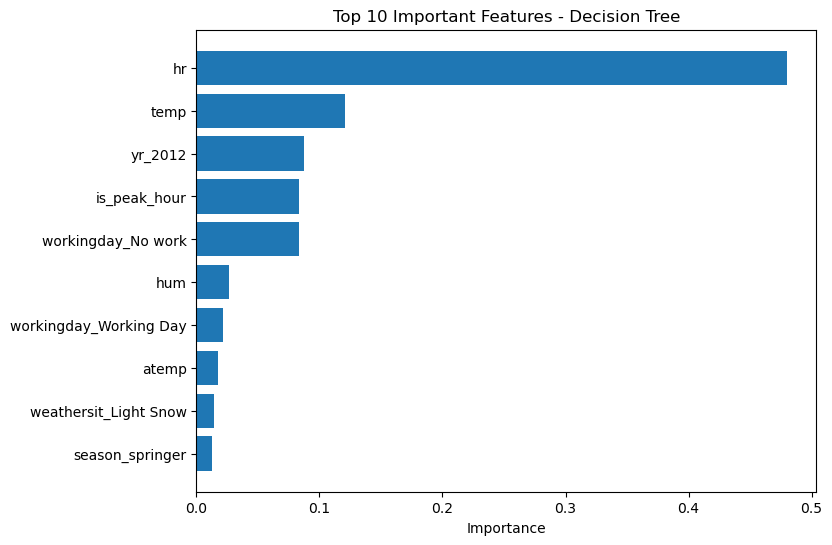

In [33]:
# Plot Top 10 Important Features

import matplotlib.pyplot as plt

top10 = importance.head(10)

plt.figure(figsize=(8,6))

plt.barh(top10['Feature'], top10['Importance'])

plt.title("Top 10 Important Features - Decision Tree")

plt.xlabel("Importance")

plt.gca().invert_yaxis()

plt.show()

### Observation

The feature importance chart shows which variables contribute the most to predicting bike rental demand.

Features with higher importance have a greater influence on the Decision Tree model's predictions.

# Model Building  2 - Random Forest Regressor

## Objective

Random Forest is an ensemble learning algorithm that builds multiple Decision Trees and combines their predictions.

It generally provides better accuracy and reduces overfitting compared to a single Decision Tree.

In this project, Random Forest Regressor is used to predict the total bike rental demand.

In [34]:
# Import Random Forest Regressor

from sklearn.ensemble import RandomForestRegressor

In [35]:
# Create Random Forest model

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train the model

rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [36]:
# Predict using Random Forest

rf_pred = rf_model.predict(X_test)

In [37]:
# Random Forest Evaluation

rf_mae = mean_absolute_error(y_test, rf_pred)

rf_mse = mean_squared_error(y_test, rf_pred)

rf_rmse = np.sqrt(rf_mse)

rf_r2 = r2_score(y_test, rf_pred)

In [38]:
print("Random Forest Performance")
print("-"*35)

print("MAE :", round(rf_mae,2))
print("MSE :", round(rf_mse,2))
print("RMSE :", round(rf_rmse,2))
print("R2 Score :", round(rf_r2,4))

Random Forest Performance
-----------------------------------
MAE : 24.46
MSE : 1688.87
RMSE : 41.1
R2 Score : 0.9467


### Observation

Random Forest combines predictions from multiple decision trees, improving accuracy and reducing the risk of overfitting compared to a single Decision Tree.

# Model Building 3 - Gradient Boosting Regressor

## Objective

Gradient Boosting is an ensemble boosting algorithm that builds trees sequentially, where each new tree attempts to correct the errors of the previous trees.

It often achieves high predictive accuracy for regression problems.

In [39]:
from sklearn.ensemble import GradientBoostingRegressor

In [40]:
gb_model = GradientBoostingRegressor(random_state=42)

gb_model.fit(X_train, y_train)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [41]:
gb_pred = gb_model.predict(X_test)

In [42]:
gb_mae = mean_absolute_error(y_test, gb_pred)

gb_mse = mean_squared_error(y_test, gb_pred)

gb_rmse = np.sqrt(gb_mse)

gb_r2 = r2_score(y_test, gb_pred)

In [43]:
print("Gradient Boosting Performance")
print("-"*35)

print("MAE :", round(gb_mae,2))
print("MSE :", round(gb_mse,2))
print("RMSE :", round(gb_rmse,2))
print("R2 Score :", round(gb_r2,4))

Gradient Boosting Performance
-----------------------------------
MAE : 44.63
MSE : 4209.4
RMSE : 64.88
R2 Score : 0.8671


### Observation

Gradient Boosting improves prediction accuracy by sequentially correcting the errors made by previous trees, making it a powerful regression algorithm.

# Model Building 4 - Linear Regression

## Objective

Linear Regression is a simple regression algorithm that models the relationship between the independent variables and the target variable.

It serves as a baseline model to compare with more advanced machine learning algorithms.

In [44]:
# Import Library

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create Model

lr = LinearRegression()

# Train Model

lr.fit(X_train, y_train)

# Prediction

lr_pred = lr.predict(X_test)

# Evaluation

lr_mae = mean_absolute_error(y_test, lr_pred)
lr_mse = mean_squared_error(y_test, lr_pred)
lr_rmse = np.sqrt(lr_mse)
lr_r2 = r2_score(y_test, lr_pred)

print("Linear Regression Performance")
print("-"*40)
print("MAE :", round(lr_mae,2))
print("MSE :", round(lr_mse,2))
print("RMSE :", round(lr_rmse,2))
print("R2 Score :", round(lr_r2,4))

Linear Regression Performance
----------------------------------------
MAE : 86.18
MSE : 13114.65
RMSE : 114.52
R2 Score : 0.5858


# Model Building 5 - Extra Trees Regressor

## Objective

Extra Trees Regressor is an ensemble learning algorithm that builds multiple randomized decision trees and combines their predictions.

It often provides high prediction accuracy while reducing overfitting.

In [45]:
# Import Library

from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create Model

et = ExtraTreesRegressor(
    n_estimators=100,
    random_state=42
)

# Train Model

et.fit(X_train, y_train)

# Prediction

et_pred = et.predict(X_test)

# Evaluation

et_mae = mean_absolute_error(y_test, et_pred)
et_mse = mean_squared_error(y_test, et_pred)
et_rmse = np.sqrt(et_mse)
et_r2 = r2_score(y_test, et_pred)

print("Extra Trees Regressor Performance")
print("-"*40)
print("MAE :", round(et_mae,2))
print("MSE :", round(et_mse,2))
print("RMSE :", round(et_rmse,2))
print("R2 Score :", round(et_r2,4))

Extra Trees Regressor Performance
----------------------------------------
MAE : 24.32
MSE : 1726.59
RMSE : 41.55
R2 Score : 0.9455


# 6. Hyperparameter Tuning

## Objective

Hyperparameter tuning is performed to optimize machine learning models by finding the best combination of parameters.

GridSearchCV with cross-validation is used to evaluate multiple parameter combinations and improve model performance.

The following models are tuned:
- Random Forest Regressor
- Decision Tree Regressor
- Gradient Boosting Regressor

# Hyperparameter Tuning - Random Forest Regressor

## Objective

Hyperparameter tuning is performed to improve the performance of the Random Forest Regressor.

GridSearchCV is used to evaluate different parameter combinations and select the model with the best R² Score using cross-validation.

In [46]:
from sklearn.model_selection import GridSearchCV

In [47]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5]
}

In [48]:
grid_rf = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=3,
    scoring='r2',
    n_jobs=-1
)

grid_rf.fit(X_train, y_train)

,estimator,RandomForestR...ndom_state=42)
,param_grid,"{'max_depth': [10, 20, ...], 'min_samples_split': [2, 5], 'n_estimators': [100, 200]}"
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,200


In [49]:
print("Best Parameters")
print(grid_rf.best_params_)

print("\nBest Cross Validation Score")
print(round(grid_rf.best_score_,4))

Best Parameters
{'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 200}

Best Cross Validation Score
0.9385


In [50]:
best_rf = grid_rf.best_estimator_

best_pred = best_rf.predict(X_test)

best_mae = mean_absolute_error(y_test, best_pred)

best_mse = mean_squared_error(y_test, best_pred)

best_rmse = np.sqrt(best_mse)

best_r2 = r2_score(y_test, best_pred)

In [51]:
print("Tuned Random Forest Performance")
print("-"*40)

print("MAE :", round(best_mae,2))
print("MSE :", round(best_mse,2))
print("RMSE :", round(best_rmse,2))
print("R2 Score :", round(best_r2,4))

Tuned Random Forest Performance
----------------------------------------
MAE : 24.43
MSE : 1681.08
RMSE : 41.0
R2 Score : 0.9469


# Hyperparameter Tuning - Decision Tree Regressor

## Objective

Hyperparameter tuning is performed to improve the performance of the Decision Tree Regressor.

GridSearchCV is used to test different parameter combinations and select the model with the best R² score.

In [52]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV

In [53]:
# Hyperparameter Tuning - Decision Tree

from sklearn.model_selection import GridSearchCV

dt_param_grid = {
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

dt_grid = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=dt_param_grid,
    cv=3,
    scoring='r2',
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

print("Best Parameters:", dt_grid.best_params_)
print("Best CV Score:", round(dt_grid.best_score_,4))

Best Parameters: {'max_depth': 15, 'min_samples_leaf': 4, 'min_samples_split': 10}
Best CV Score: 0.9025


In [54]:
# Evaluate Tuned Decision Tree

best_dt = dt_grid.best_estimator_

dt_tuned_pred = best_dt.predict(X_test)

dt_tuned_mae = mean_absolute_error(y_test, dt_tuned_pred)
dt_tuned_mse = mean_squared_error(y_test, dt_tuned_pred)
dt_tuned_rmse = np.sqrt(dt_tuned_mse)
dt_tuned_r2 = r2_score(y_test, dt_tuned_pred)

print("Tuned Decision Tree Performance")
print("-"*35)
print("MAE :", round(dt_tuned_mae,2))
print("MSE :", round(dt_tuned_mse,2))
print("RMSE :", round(dt_tuned_rmse,2))
print("R2 Score :", round(dt_tuned_r2,4))

Tuned Decision Tree Performance
-----------------------------------
MAE : 31.05
MSE : 2735.38
RMSE : 52.3
R2 Score : 0.9136


### Observation

The Decision Tree Regressor was optimized using GridSearchCV.

The tuned model achieved improved performance by selecting the best combination of hyperparameters based on cross-validation.

# Hyperparameter Tuning - Gradient Boosting Regressor

## Objective

Hyperparameter tuning is performed to identify the best parameter values for the Gradient Boosting Regressor.

GridSearchCV evaluates multiple parameter combinations and selects the model with the highest R² Score using cross-validation.

In [55]:
 # Hyperparameter Tuning - Gradient Boosting

gb_param_grid = {
    'n_estimators': [100, 150, 200],
    'learning_rate': [0.05, 0.1, 0.2],
    'max_depth': [3, 5],
    'min_samples_split': [2, 5]
}

gb_grid = GridSearchCV(
    estimator=GradientBoostingRegressor(random_state=42),
    param_grid=gb_param_grid,
    scoring='r2',
    cv=3,
    n_jobs=-1
)

gb_grid.fit(X_train, y_train)

print("Best Parameters :", gb_grid.best_params_)
print("Best CV Score :", round(gb_grid.best_score_,4))                                                                    

Best Parameters : {'learning_rate': 0.2, 'max_depth': 5, 'min_samples_split': 2, 'n_estimators': 200}
Best CV Score : 0.9455


In [56]:
# Evaluate Tuned Gradient Boosting

best_gb = gb_grid.best_estimator_

gb_tuned_pred = best_gb.predict(X_test)

gb_tuned_mae = mean_absolute_error(y_test, gb_tuned_pred)
gb_tuned_mse = mean_squared_error(y_test, gb_tuned_pred)
gb_tuned_rmse = np.sqrt(gb_tuned_mse)
gb_tuned_r2 = r2_score(y_test, gb_tuned_pred)

print("Tuned Gradient Boosting Performance")
print("-"*40)

print("MAE :", round(gb_tuned_mae,2))
print("MSE :", round(gb_tuned_mse,2))
print("RMSE :", round(gb_tuned_rmse,2))
print("R2 Score :", round(gb_tuned_r2,4))

Tuned Gradient Boosting Performance
----------------------------------------
MAE : 25.4
MSE : 1636.68
RMSE : 40.46
R2 Score : 0.9483


### Observation

The Gradient Boosting Regressor was optimized using GridSearchCV.

The tuned model was evaluated using MAE, MSE, RMSE, and R² Score. The optimized hyperparameters improved the predictive performance and generalization capability of the model.

# 7. Model Evaluation and Comparison

## Objective

The performance of all regression models is compared using MAE, RMSE, and R² Score.

The best-performing model is selected based on the highest R² Score and the lowest prediction errors.

In [57]:
comparison = pd.DataFrame({

    'Model': [

        'Linear Regression',
        'Decision Tree',
        'Tuned Decision Tree',
        'Random Forest',
        'Tuned Random Forest',
        'Gradient Boosting',
        'Tuned Gradient Boosting',
        'Extra Trees'

    ],

    'MAE': [

        lr_mae,
        dt_mae,
        dt_tuned_mae,
        rf_mae,
        best_mae,
        gb_mae,
        gb_tuned_mae,
        et_mae

    ],

    'RMSE': [

        lr_rmse,
        dt_rmse,
        dt_tuned_rmse,
        rf_rmse,
        best_rmse,
        gb_rmse,
        gb_tuned_rmse,
        et_rmse

    ],

    'R2 Score': [

        lr_r2,
        dt_r2,
        dt_tuned_r2,
        rf_r2,
        best_r2,
        gb_r2,
        gb_tuned_r2,
        et_r2

    ]

})

comparison = comparison.sort_values(by='R2 Score', ascending=False)

comparison

,Model,MAE,RMSE,R2 Score
6,Tuned Gradient Boosting,25.401553,40.455942,0.948313
4,Tuned Random Forest,24.434174,41.000917,0.946911
3,Random Forest,24.463185,41.095862,0.946665
7,Extra Trees,24.318728,41.552307,0.945474
2,Tuned Decision Tree,31.050518,52.300837,0.913616
1,Decision Tree,33.955696,59.027270,0.889968
5,Gradient Boosting,44.632065,64.879901,0.867066
0,Linear Regression,86.179743,114.519203,0.585837


### Observation

Among all the regression models, the Tuned Gradient Boosting Regressor achieved the highest R² Score (0.9483) and the lowest RMSE (40.46), indicating the best overall predictive performance.

Although the Extra Trees Regressor produced the lowest MAE, the Tuned Gradient Boosting model demonstrated better overall performance across multiple evaluation metrics and was therefore selected as the final model.

# 8. Best Model Selection

## Objective

The performance of all regression models was compared using MAE, RMSE, and R² Score.

The model with the highest R² Score and the lowest prediction error was selected as the final model for bike rental demand prediction.

In [58]:
best_model = comparison.iloc[0]

print("Best Model Selected")
print("-"*35)

print("Model :", best_model["Model"])
print("MAE :", round(best_model["MAE"],2))
print("RMSE :", round(best_model["RMSE"],2))
print("R2 Score :", round(best_model["R2 Score"],4))

Best Model Selected
-----------------------------------
Model : Tuned Gradient Boosting
MAE : 25.4
RMSE : 40.46
R2 Score : 0.9483


# 9.Final Model Selection and Conclusion

## Best Model Selection

Eight regression models were evaluated for predicting bike rental demand:

- Linear Regression
- Decision Tree Regressor
- Tuned Decision Tree Regressor
- Random Forest Regressor
- Tuned Random Forest Regressor
- Gradient Boosting Regressor
- Tuned Gradient Boosting Regressor
- Extra Trees Regressor

The models were compared using MAE, RMSE, and R² Score.

Among all the models, the **Tuned Gradient Boosting Regressor** achieved the highest **R² Score (0.9483)** while maintaining a low **RMSE (40.46)** and **MAE (25.40)**. Therefore, it was selected as the final model for this project.

Although the **Extra Trees Regressor** and **Random Forest Regressor** also performed well, their R² Scores were slightly lower than the Tuned Gradient Boosting model.

## Conclusion

This project successfully developed a machine learning model to predict hourly bike rental demand.

The dataset was cleaned, validated, visualized, and prepared through preprocessing techniques such as handling missing values, encoding categorical variables, feature engineering, and feature scaling.

Multiple regression algorithms were trained and evaluated to compare their performance. Hyperparameter tuning further improved the performance of the tree-based models.

Based on the evaluation metrics, the **Tuned Gradient Boosting Regressor** was selected as the best-performing model with:
- **MAE:** 25.40
- **RMSE:** 40.46
- **R² Score:** 0.9483

This model provides accurate predictions and can help bike rental companies estimate customer demand, optimize bike availability, improve resource planning, and support data-driven decision-making.